# 1. Exploratory data analysis
Review data quality, distributions, relationships with attrition, correlations, outliers and hypothesis-test examples.

EDA retains the original 5,030 rows to preserve the earlier analysis. Thirty exact duplicates are identified here and removed before modelling in Notebook 2. Earlier EDA viewed the full dataset; this is not a blind test assessment. Employee ID is excluded from predictor plots/correlations. Associations do not establish causes.

In [1]:
# Import the tools used in this notebook.
import os
for setting in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[setting] = '1'
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
# Locate the repository even before its local data has been downloaded.
from pathlib import Path
PROJECT = Path.cwd()
if not (PROJECT / '01_EDA.ipynb').exists():
    PROJECT = PROJECT / 'attrition'
assert (PROJECT / '01_EDA.ipynb').exists(), 'Open from the repository root or its parent.'

In [ ]:
# Translate the downloaded Kaggle CSV only when the English copy is missing.
import hashlib
raw_folder = PROJECT / 'data/raw'
raw_folder.mkdir(parents=True, exist_ok=True)
english_file = raw_folder / 'employee_attrition_data_english.csv'
expected_hash = '5570f114b577c6defac13e010bc8ca1b152f286322c1d9b1fa6f413c10114d90'
if not english_file.exists():
    source_file = raw_folder / 'employee_attrition_data.csv'
    assert source_file.exists(), 'Download the Kaggle CSV into data/raw first. See data/README.md.'
    translated = pd.read_csv(source_file)
    translations = {
        'gender': {'男': 'Male', '女': 'Female'},
        'marital_status': {'未婚': 'Single', '已婚': 'Married', '离异': 'Divorced'},
        'education': {'大专': 'Associate degree', '本科': "Bachelor's degree",
                      '硕士': "Master's degree", '博士': 'Doctorate'},
        'department': {'技术部': 'Technology', '运营部': 'Operations', '财务部': 'Finance',
                       '销售部': 'Sales', '市场部': 'Marketing', '人力资源部': 'Human Resources',
                       '客服部': 'Customer Service', '产品部': 'Product'},
        'job_level': {'初级': 'Junior', '中级': 'Mid-level', '高级': 'Senior',
                      '管理层': 'Management', '资深': 'Expert'},
        'travel_frequency': {'无': 'Never', '偶尔': 'Occasionally', '经常': 'Frequently'}
    }
    for column, mapping in translations.items():
        unknown = set(translated[column].dropna()) - set(mapping) - set(mapping.values())
        assert not unknown, f'Review untranslated values in {column}: {unknown}'
        translated[column] = translated[column].replace(mapping).astype(object)
    contents = translated.to_csv(index=False).encode('utf-8')
    assert hashlib.sha256(contents).hexdigest() == expected_hash, 'Dataset differs from the study. See data/README.md.'
    english_file.write_bytes(contents)
assert hashlib.sha256(english_file.read_bytes()).hexdigest() == expected_hash, 'English CSV differs from the study.'
print('English dataset ready; missing values preserved.')


In [2]:
# Read English data and identify exact duplicate rows.
emp = pd.read_csv(PROJECT / 'data/raw/employee_attrition_data_english.csv')
assert emp['employee_id'].notna().all() and emp['attrition'].isin([0, 1]).all()
emp_validated = emp.drop_duplicates().copy()
assert emp_validated['employee_id'].is_unique
print('Original rows:', len(emp), '| Exact duplicates removed:', len(emp) - len(emp_validated))

Original rows: 5030 | Exact duplicates removed: 30


## Data overview and missing values

In [3]:
# Analyse the variables shown below.
emp.head(), emp.shape

Out[3]: 
(  employee_id   age  gender  ... late_count leave_days attrition
 0      E20001  24.0    Male  ...        3.0        1.0         0
 1      E20002  39.0    Male  ...        1.0        0.0         0
 2      E20003  29.0  Female  ...        0.0        8.0         0
 3      E20004  33.0  Female  ...        1.0        2.0         0
 4      E20005  36.0    Male  ...        4.3        1.0         0
 
 [5 rows x 27 columns],
 (5030, 27))


In [4]:
# Analyse the variables shown below.
emp.describe(include='all').T

Out[4]: 
                        count unique  ...      75%      max
employee_id              5030   5000  ...      NaN      NaN
age                    5018.0    NaN  ...     36.0     58.0
gender                   5015      2  ...      NaN      NaN
marital_status           5014      3  ...      NaN      NaN
education                5012      4  ...      NaN      NaN
department               5014      8  ...      NaN      NaN
job_level                5007      5  ...      NaN      NaN
total_work_years       5018.0    NaN  ...      5.0     21.0
tenure                 5010.0    NaN  ...      2.0     18.0
monthly_salary         5012.0    NaN  ...  18264.0  49024.0
salary_hike_pct        5019.0    NaN  ...     15.0     32.1
years_since_promotion  5021.0    NaN  ...      1.0     10.0
training_times         5014.0    NaN  ...      3.0      8.0
overtime_hours         5015.0    NaN  ...    17.55     80.0
travel_frequency         5013      3  ...      NaN      NaN
job_satisfaction       5005.0  

In [5]:
# Analyse the variables shown below.
emp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   employee_id            5030 non-null   object 
 1   age                    5018 non-null   float64
 2   gender                 5015 non-null   object 
 3   marital_status         5014 non-null   object 
 4   education              5012 non-null   object 
 5   department             5014 non-null   object 
 6   job_level              5007 non-null   object 
 7   total_work_years       5018 non-null   float64
 8   tenure                 5010 non-null   float64
 9   monthly_salary         5012 non-null   float64
 10  salary_hike_pct        5019 non-null   float64
 11  years_since_promotion  5021 non-null   float64
 12  training_times         5014 non-null   float64
 13  overtime_hours         5015 non-null   float64
 14  travel_frequency       5013 non-null   object 
 15  job_

In [6]:
# Analyse the variables shown below.
emp.isna().sum()

Out[6]: 
employee_id               0
age                      12
gender                   15
marital_status           16
education                18
department               16
job_level                23
total_work_years         12
tenure                   20
monthly_salary           18
salary_hike_pct          11
years_since_promotion     9
training_times           16
overtime_hours           15
travel_frequency         17
job_satisfaction         25
env_satisfaction         15
job_involvement          12
relationship_score       14
performance_rating       17
work_life_balance         8
commute_distance          9
num_companies            13
num_projects             13
late_count               13
leave_days               20
attrition                 0
dtype: int64


In [7]:
# count total number of null values in the data
emp.isna().sum().sum()

Out[7]: 377


In [8]:
# Analyse the variables shown below.
cat_cols = emp.select_dtypes(include=['object','string','category']).columns.to_list()
num_cols = emp.select_dtypes(include= "number").columns.tolist()

print("Categorical columns = ",cat_cols)
print("Numerical columns = ",num_cols)

Categorical columns =  ['employee_id', 'gender', 'marital_status', 'education', 'department', 'job_level', 'travel_frequency']
Numerical columns =  ['age', 'total_work_years', 'tenure', 'monthly_salary', 'salary_hike_pct', 'years_since_promotion', 'training_times', 'overtime_hours', 'job_satisfaction', 'env_satisfaction', 'job_involvement', 'relationship_score', 'performance_rating', 'work_life_balance', 'commute_distance', 'num_companies', 'num_projects', 'late_count', 'leave_days', 'attrition']


In [9]:
# Analyse the variables shown below.
for col in cat_cols:
    print("Unique values in column : ",emp[col].unique())

Unique values in column :  ['E20001' 'E20002' 'E20003' ... 'E24998' 'E24999' 'E25000']
Unique values in column :  ['Male' 'Female' nan]
Unique values in column :  ['Single' 'Married' 'Divorced' nan]
Unique values in column :  ["Master's degree" "Bachelor's degree" 'Associate degree' 'Doctorate' nan]
Unique values in column :  ['Technology' 'Operations' 'Finance' 'Sales' 'Marketing' 'Human Resources'
 'Customer Service' 'Product' nan]
Unique values in column :  ['Mid-level' 'Senior' 'Junior' 'Management' 'Expert' nan]
Unique values in column :  ['Occasionally' 'Never' 'Frequently' nan]


## Univariate analysis

In [10]:
# Analyse the variables shown below.
X = emp.drop(columns=["employee_id", "attrition"])
cat_cols = X.select_dtypes(exclude="number").columns
num_cols = X.select_dtypes(include="number").columns

,Count,Percentage
attrition,,
0,4211,83.72
1,819,16.28


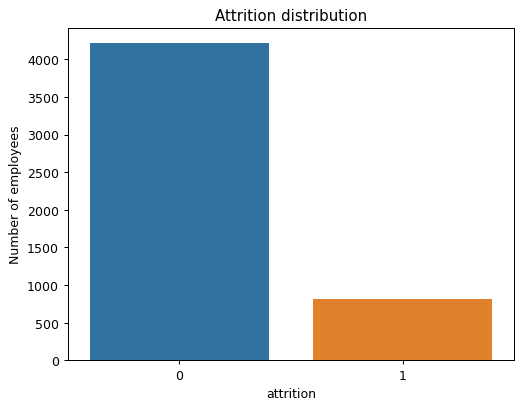

In [11]:
# Analyse the variables shown below.
display(emp["attrition"].value_counts(dropna=False).to_frame("Count").assign(
    Percentage=lambda x: (100 * x["Count"] / len(emp)).round(2)
))

sns.countplot(data=emp, x="attrition")
plt.title("Attrition distribution")
plt.ylabel("Number of employees")
plt.show()

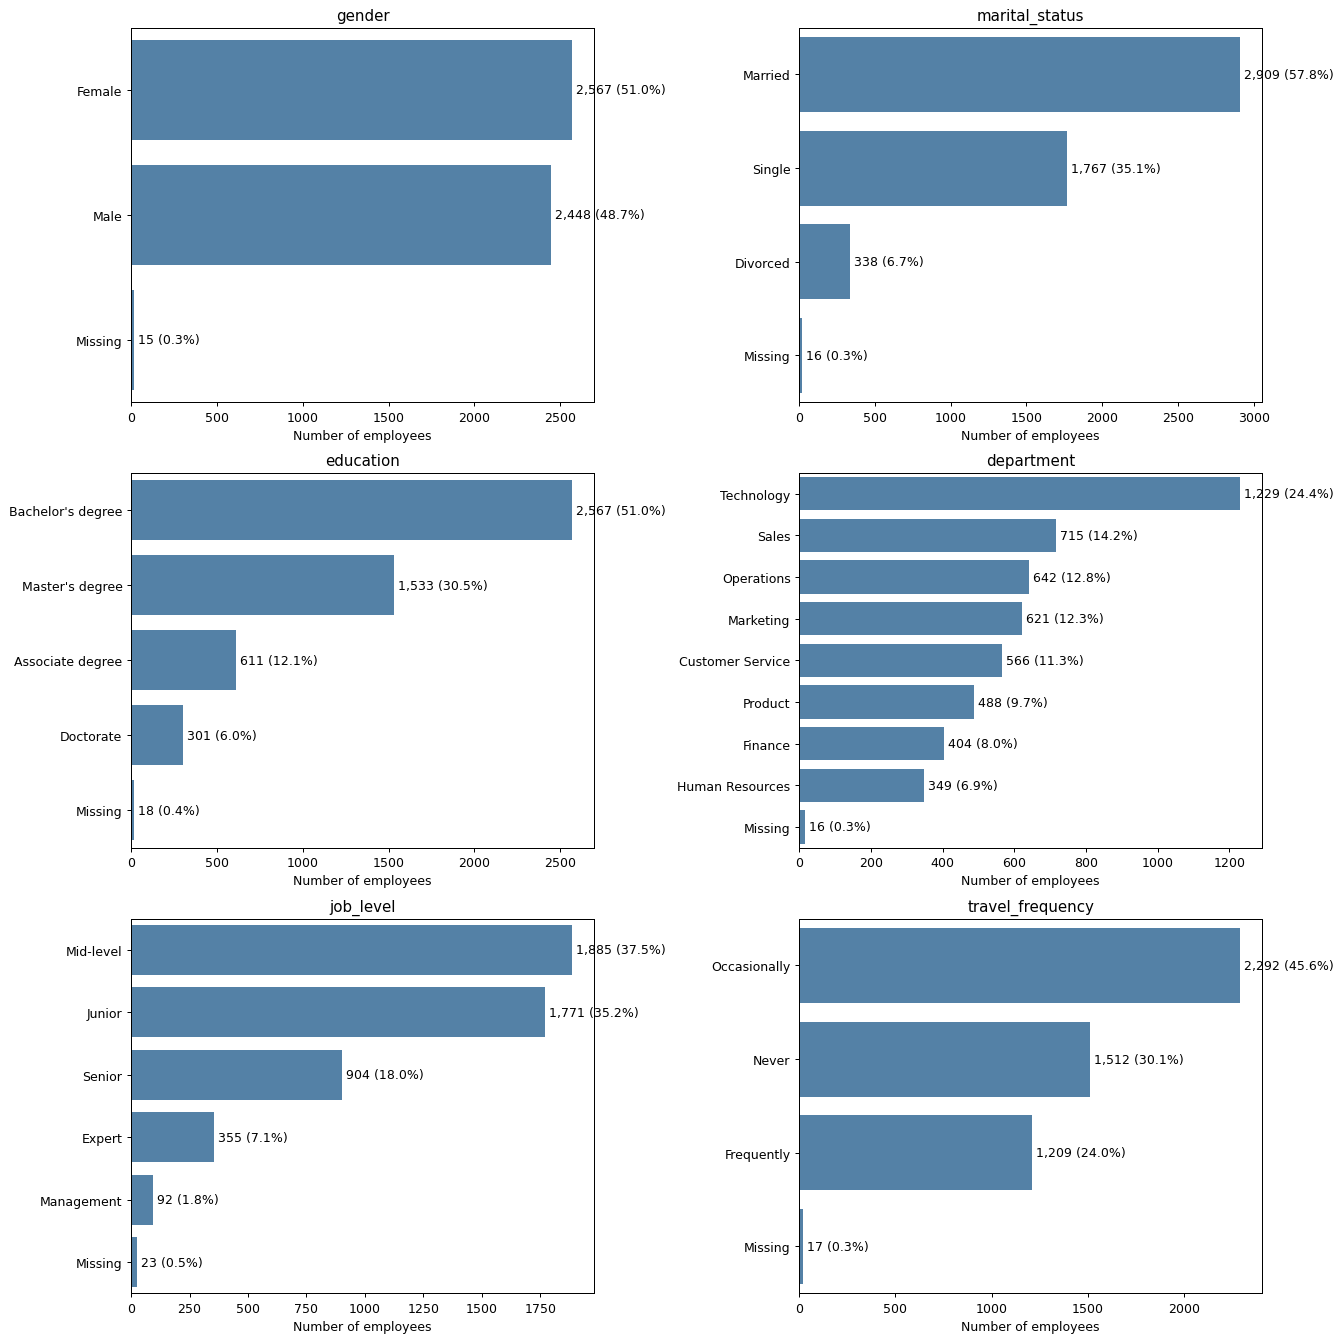

In [12]:
# Categorical distribution
fig, axes = plt.subplots(3, 2, figsize=(15, 15))

for col, ax in zip(cat_cols, axes.flat):
    s = emp[col].fillna("Missing")
    sns.countplot(y=s, order=s.value_counts().index, ax=ax, color="steelblue")
    ax.set(title=col, xlabel="Number of employees", ylabel="")

    for bar in ax.patches:
        n = int(bar.get_width())
        ax.text(n, bar.get_y() + bar.get_height()/2,
                f" {n:,} ({n/len(emp):.1%})", va="center")

plt.tight_layout()
plt.show()

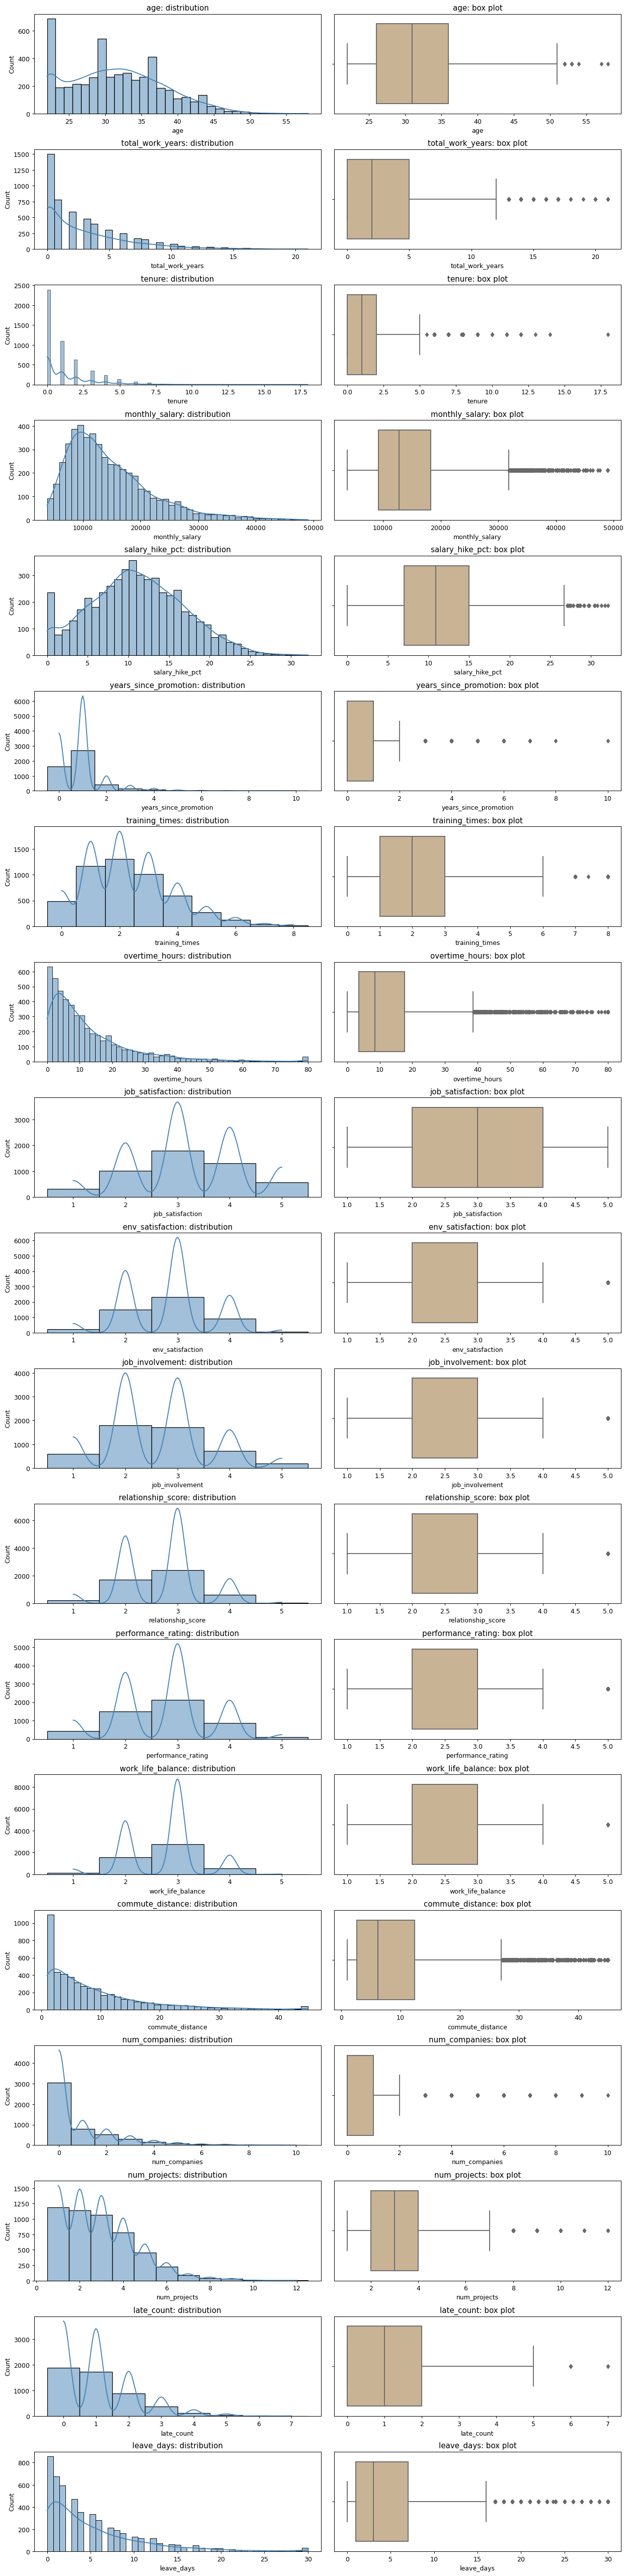

C:\Users\heman\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\heman\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\heman\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\heman\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating

In [13]:
#numerical distribution
fig, axes = plt.subplots(len(num_cols), 2, figsize=(14, 3 * len(num_cols)))

for col, (hist_ax, box_ax) in zip(num_cols, axes):
    sns.histplot(data=emp, x=col,kde=True, discrete=emp[col].nunique() <= 15,
                 ax=hist_ax, color="steelblue")
    sns.boxplot(data=emp, x=col, ax=box_ax, color="tan")
    hist_ax.set_title(f"{col}: distribution")
    box_ax.set_title(f"{col}: box plot")

plt.tight_layout()
plt.show()

## Bivariate analysis against attrition

In [14]:
# Analyse the variables shown below.
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

eda = emp.dropna(subset=["attrition"])
features = eda.drop(columns=["employee_id", "attrition"])

cat_cols = features.select_dtypes(exclude="number").columns
num_cols = features.select_dtypes(include="number").columns

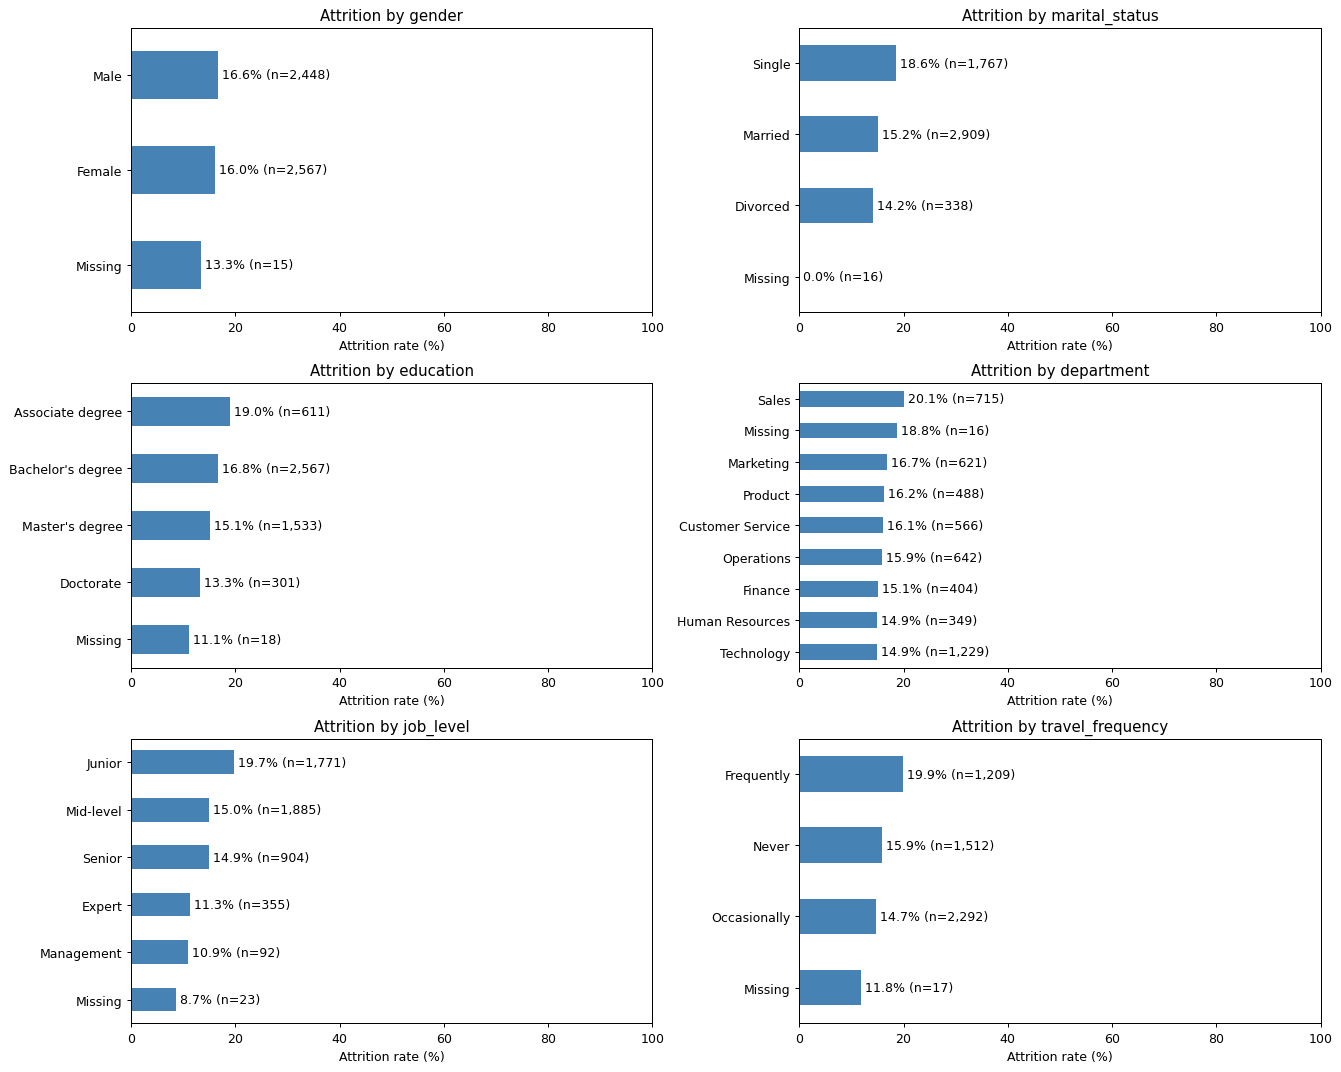

In [15]:
# Analyse the variables shown below.
fig, axes = plt.subplots(
    int(np.ceil(len(cat_cols) / 2)), 2,
    figsize=(15, 4 * int(np.ceil(len(cat_cols) / 2))),
    squeeze=False
)

for col, ax in zip(cat_cols, axes.flat):
    summary = eda.groupby(eda[col].fillna("Missing"))["attrition"].agg(
        Employees="size", Attrition_rate="mean"
    ).sort_values("Attrition_rate", ascending=False)

    summary["Attrition_rate"].mul(100).plot.barh(ax=ax, color="steelblue")
    ax.set(title=f"Attrition by {col}", xlabel="Attrition rate (%)", ylabel="")
    ax.invert_yaxis()

    for bar, n in zip(ax.patches, summary["Employees"]):
        ax.text(bar.get_width(), bar.get_y() + bar.get_height()/2,
                f" {bar.get_width():.1f}% (n={n:,})", va="center")

    ax.set_xlim(0, max(100, ax.get_xlim()[1]))

for ax in axes.flat[len(cat_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

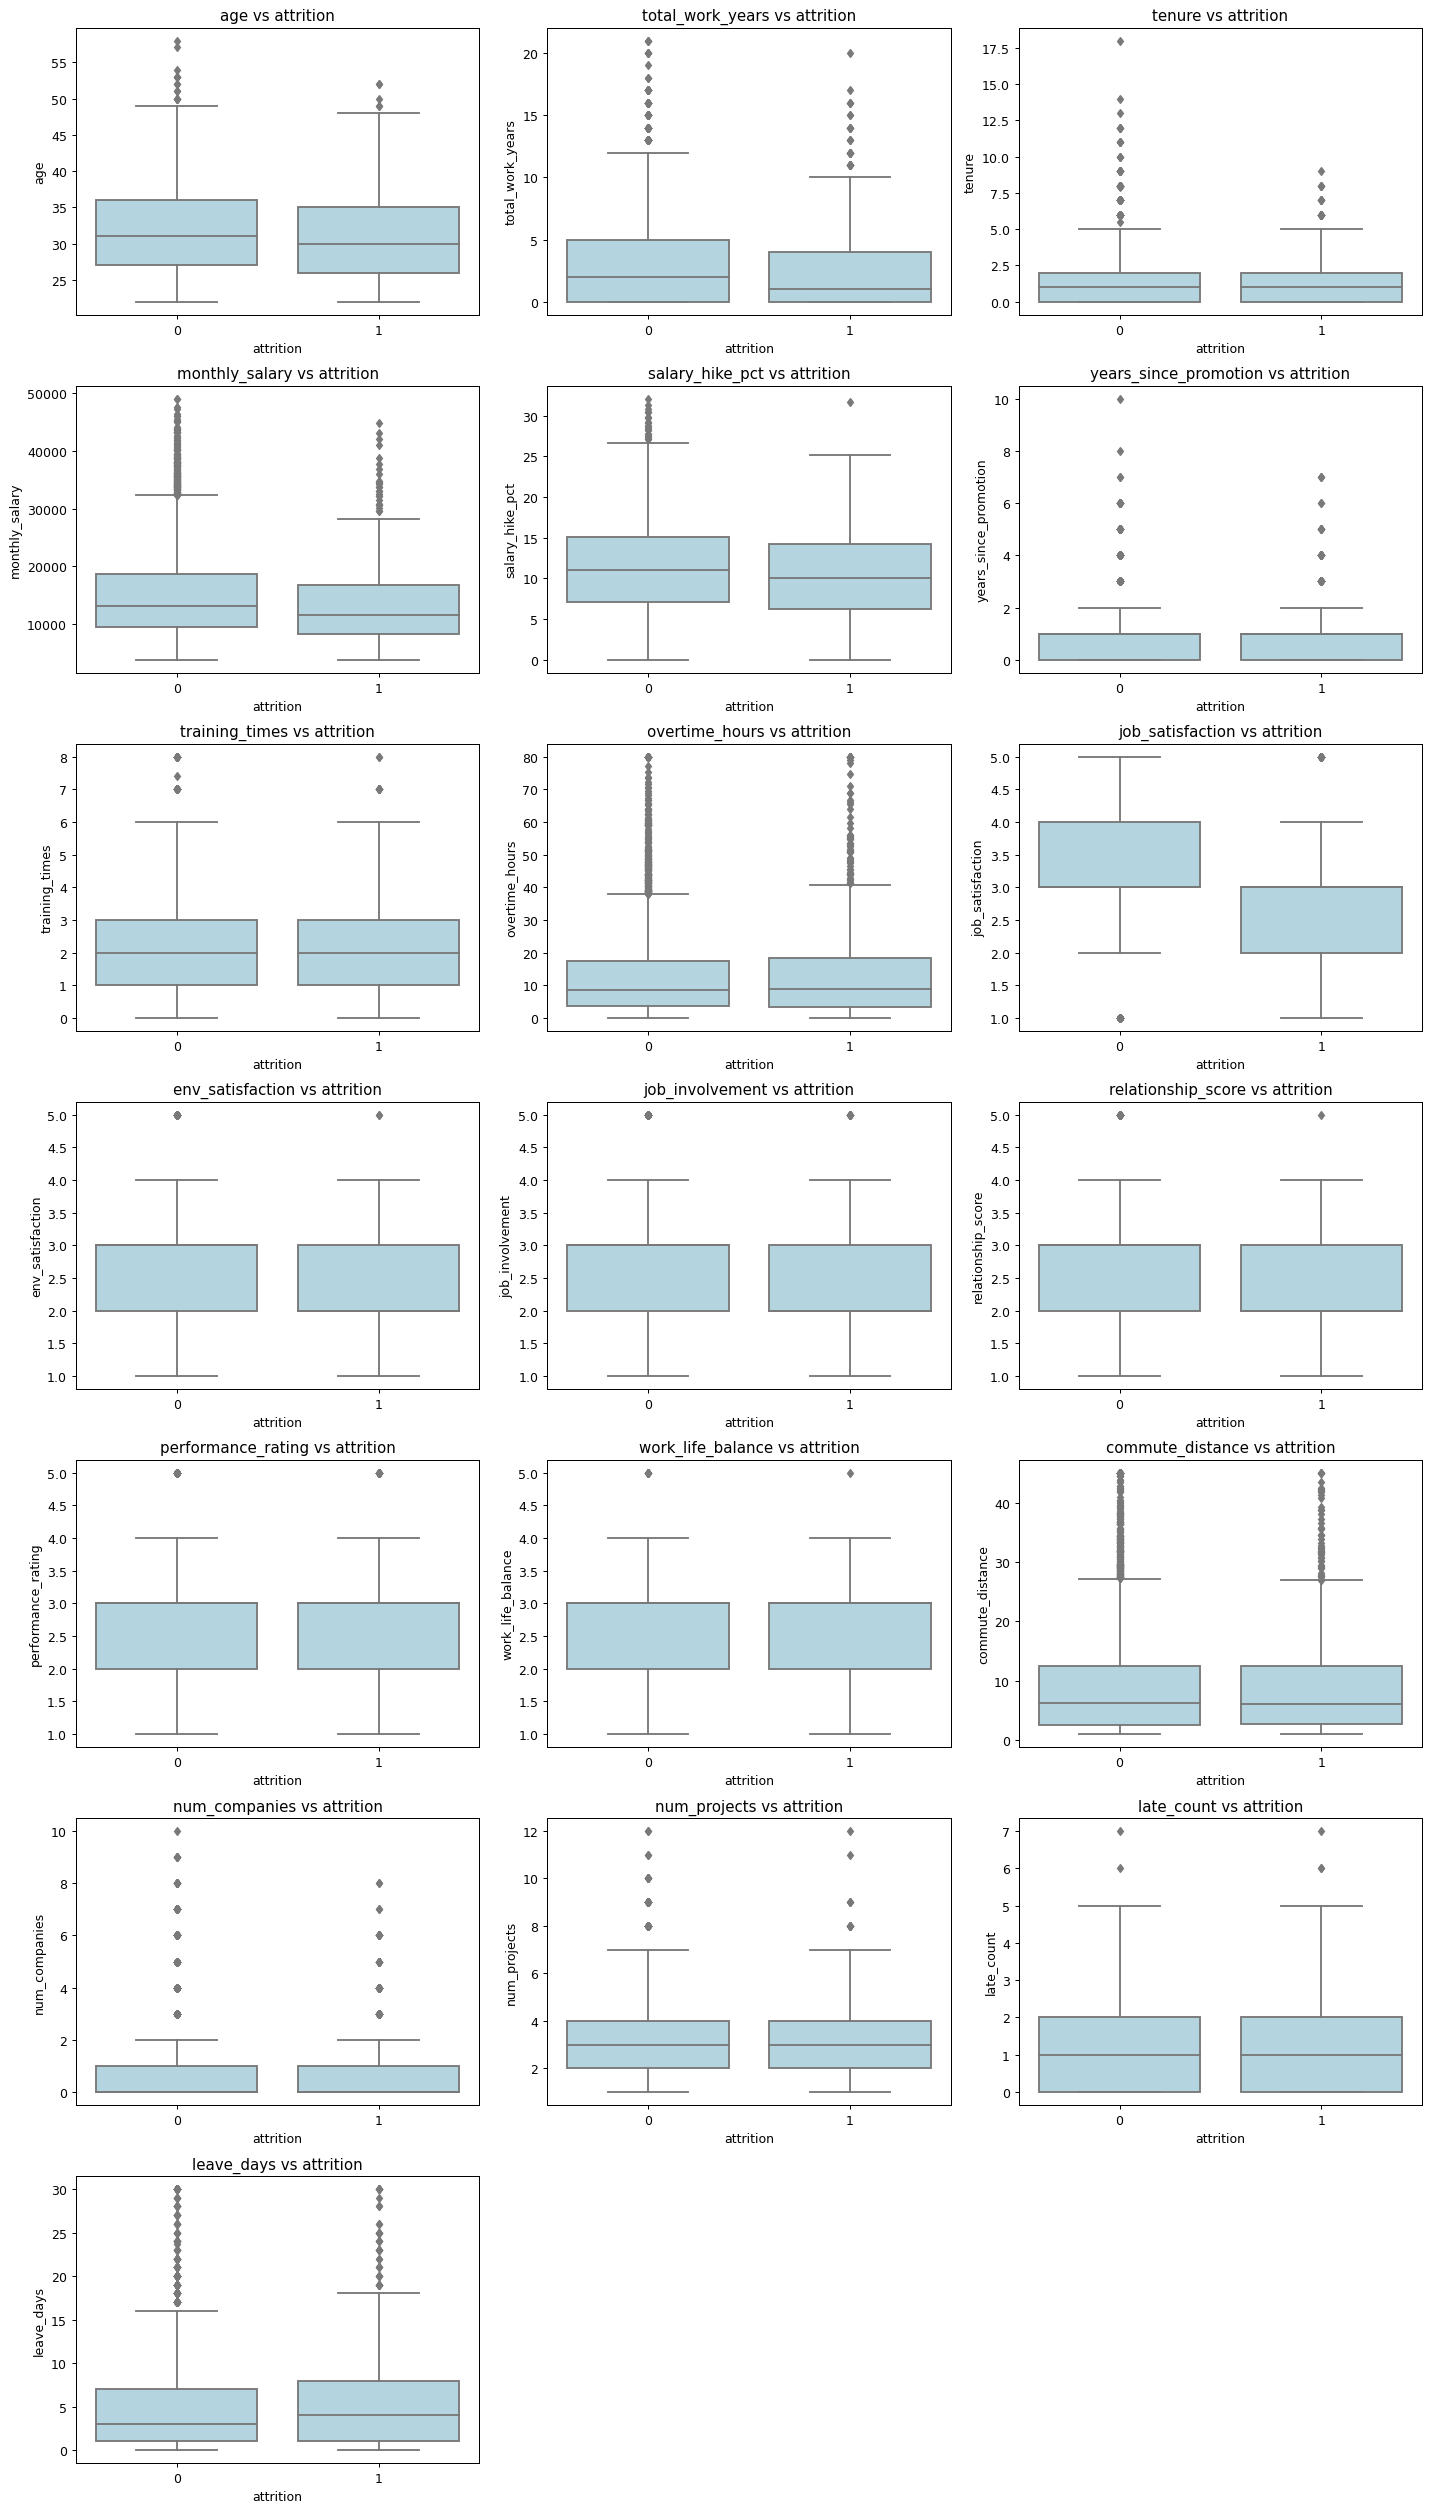

attrition                      0       1
age              count   4200.00  818.00
                 mean      31.71   31.00
                 std        6.53    6.56
                 median    31.00   30.00
total_work_years count   4203.00  815.00
...                          ...     ...
late_count       median     1.00    1.00
leave_days       count   4196.00  814.00
                 mean       5.07    5.70
                 std        5.60    5.98
                 median     3.00    4.00

[76 rows x 2 columns]

In [16]:
# Analyse the variables shown below.
fig, axes = plt.subplots(
    int(np.ceil(len(num_cols) / 3)), 3,
    figsize=(16, 4 * int(np.ceil(len(num_cols) / 3))),
    squeeze=False
)

for col, ax in zip(num_cols, axes.flat):
    sns.boxplot(data=eda, x="attrition", y=col, ax=ax, color="lightblue")
    ax.set_title(f"{col} vs attrition")

for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

display(eda.groupby("attrition")[num_cols].agg(["count", "mean","std" ,"median"]).T.round(2))

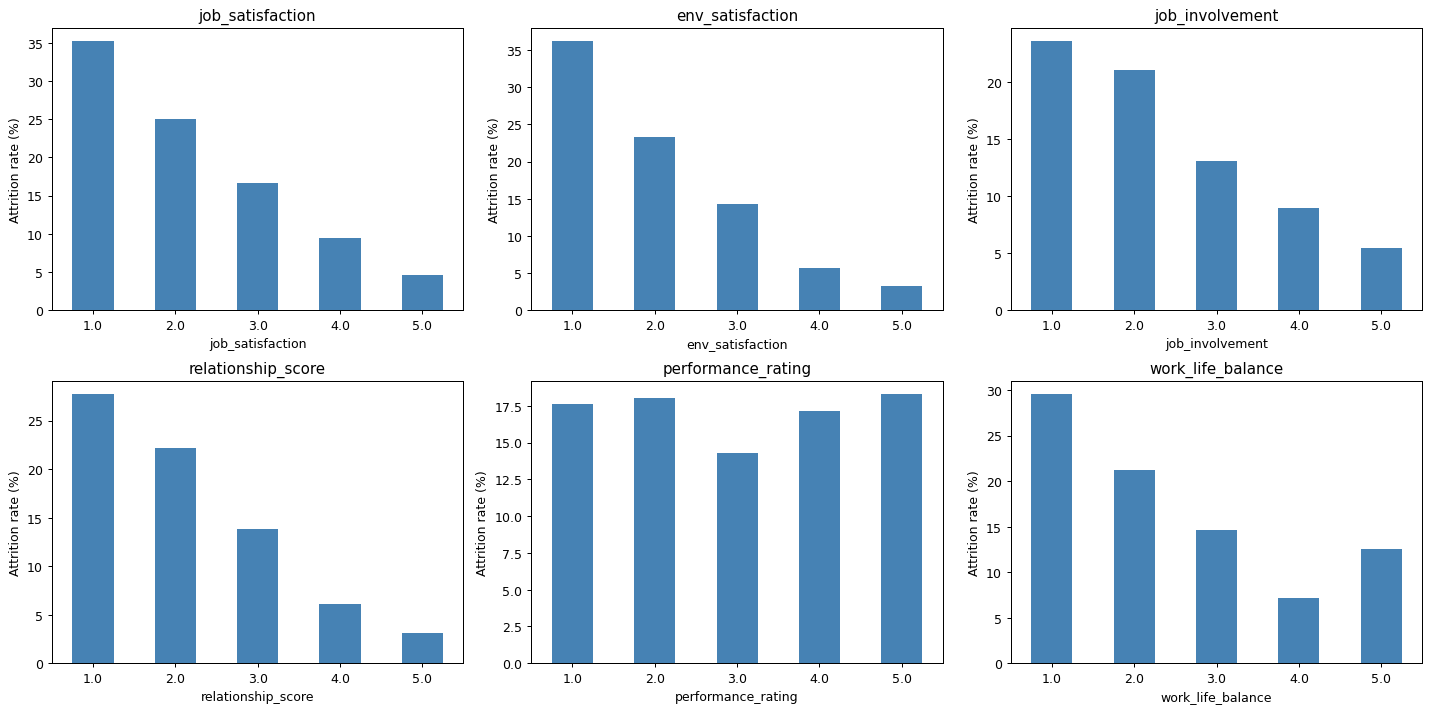

In [17]:
# Analyse the variables shown below.
rating_cols = [
    "job_satisfaction", "env_satisfaction", "job_involvement",
    "relationship_score", "performance_rating", "work_life_balance"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for col, ax in zip(rating_cols, axes.flat):
    eda.groupby(col)["attrition"].mean().mul(100).plot.bar(
        ax=ax, color="steelblue", rot=0
    )
    ax.set(title=col, ylabel="Attrition rate (%)")

plt.tight_layout()
plt.show()

## Numerical correlation analysis

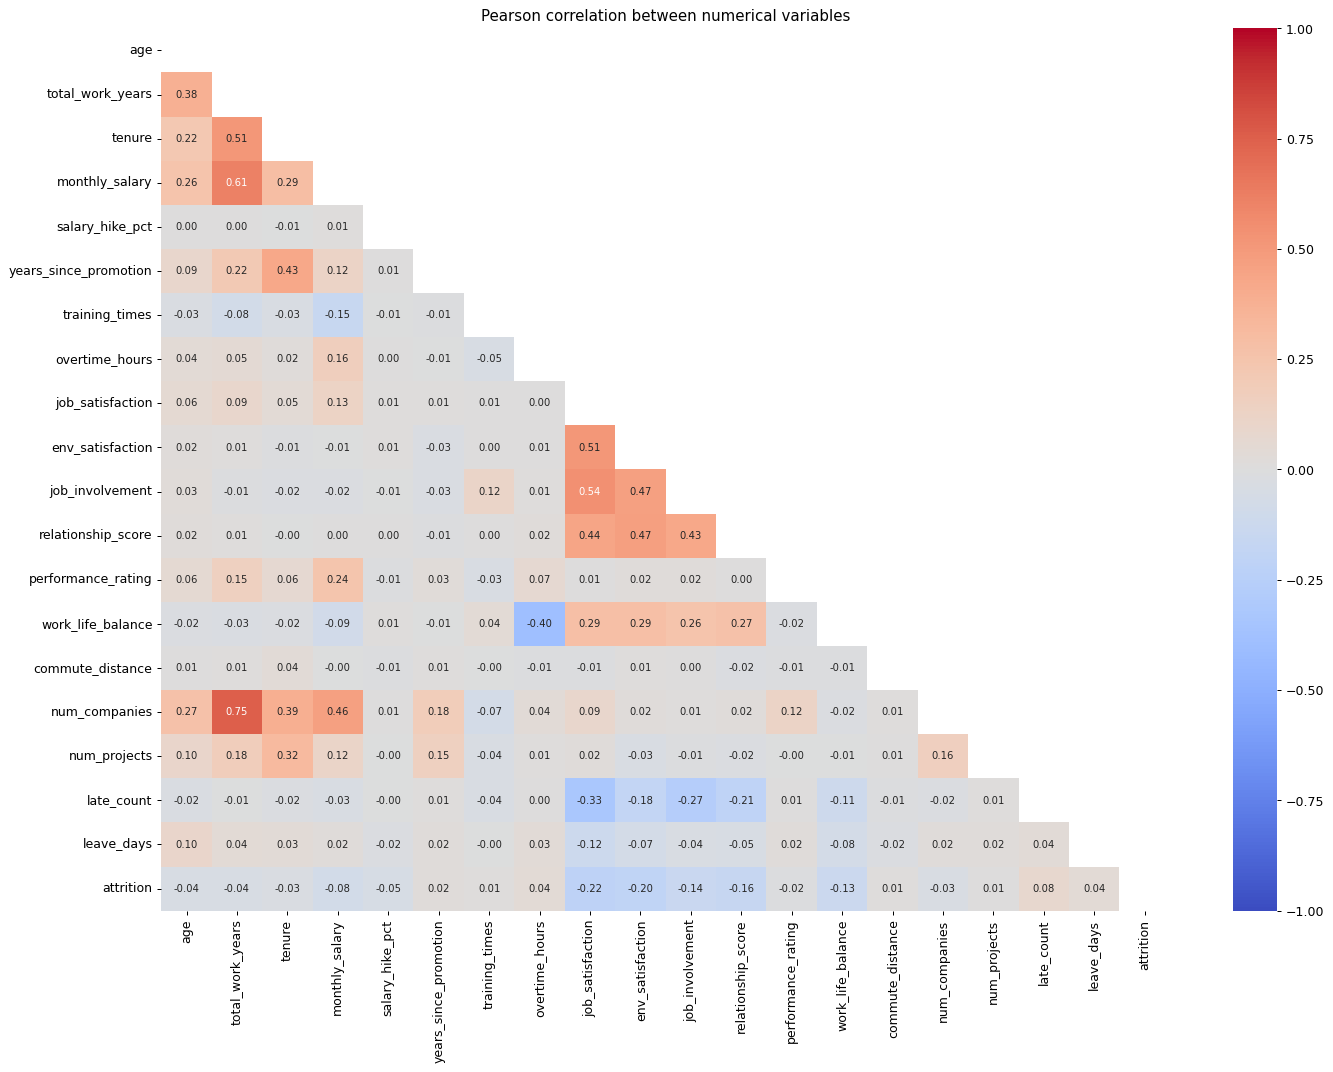

In [18]:
# Analyse the variables shown below.
numeric = eda.drop(columns="employee_id").select_dtypes(include="number")

pearson = numeric.corr(method="pearson")
spearman = numeric.corr(method="spearman")

plt.figure(figsize=(16, 12))
sns.heatmap(
    pearson, mask=np.triu(np.ones_like(pearson, dtype=bool)),
    annot=True, fmt=".2f", cmap="coolwarm", center=0,
    vmin=-1, vmax=1, annot_kws={"size": 8}
)
plt.title("Pearson correlation between numerical variables")
plt.tight_layout()
plt.show()

,Pearson,Spearman
job_satisfaction,-0.217,-0.215
env_satisfaction,-0.202,-0.199
relationship_score,-0.159,-0.159
job_involvement,-0.144,-0.146
work_life_balance,-0.130,-0.128
monthly_salary,-0.082,-0.089
late_count,0.079,0.077
salary_hike_pct,-0.054,-0.054
overtime_hours,0.043,0.016
total_work_years,-0.042,-0.042


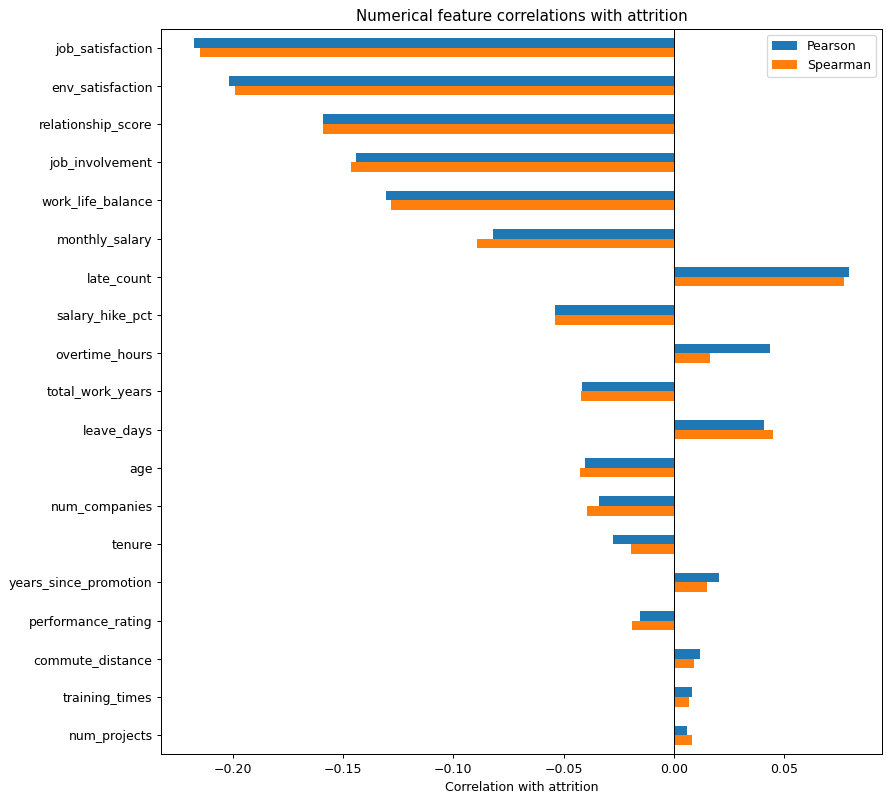

In [19]:
# Analyse the variables shown below.
target_corr = pd.DataFrame({
    "Pearson": pearson["attrition"],
    "Spearman": spearman["attrition"]
}).drop(index="attrition")

target_corr = target_corr.loc[
    target_corr["Pearson"].abs().sort_values(ascending=False).index
]

display(target_corr.round(3))

target_corr.plot.barh(figsize=(10, 9))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Correlation with attrition")
plt.title("Numerical feature correlations with attrition")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Hypothesis tests: two examples of each test

One-sample benchmarks of 20 overtime hours and 3 tenure years are illustrative, not approved business standards. Welch tests compare leavers with stayers; chi-square tests assess categorical association; ANOVA compares department means among leavers. Holm adjustment covers all eight examples.

Tests assume independent observations; duplicates weaken that assumption. ANOVA also assumes roughly normal errors and equal variances, which were not established here. Treat these as demonstrations, not confirmatory feature-selection evidence. Missing values are excluded per test.

In [20]:
# Analyse the variables shown below.
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

data = emp.dropna(subset=["attrition"])
results = []

def record(test, case, statistic, p):
    results.append([test, case, statistic, p])

In [21]:
# Analyse the variables shown below.
leavers = data[data["attrition"] == 1]

for col, benchmark in [("overtime_hours", 20), ("tenure", 3)]:
    sample = leavers[col].dropna()
    t, p = stats.ttest_1samp(sample, popmean=benchmark)

    record("One-sample t-test", f"Leavers: {col} vs {benchmark}", t, p)
    print(f"{col}: n={len(sample)}, mean={sample.mean():.2f}")

overtime_hours: n=819, mean=14.21
tenure: n=817, mean=1.13


In [22]:
# Analyse the variables shown below.
for col in ["monthly_salary", "overtime_hours"]:
    stayed = data.loc[data["attrition"] == 0, col].dropna()
    left = data.loc[data["attrition"] == 1, col].dropna()

    t, p = stats.ttest_ind(stayed, left, equal_var=False)

    record("Welch two-sample t-test", f"{col} by attrition", t, p)
    print(f"{col}: stayed={stayed.mean():.2f}, left={left.mean():.2f}, "
          f"difference (left − stayed)={left.mean() - stayed.mean():.2f}")

monthly_salary: stayed=14875.87, left=13224.36, difference (left − stayed)=-1651.51
overtime_hours: stayed=12.60, left=14.21, difference (left − stayed)=1.60


In [23]:
# Analyse the variables shown below.
for col in ["department", "travel_frequency"]:
    table = pd.crosstab(data[col], data["attrition"])
    chi2, p, dof, expected = stats.chi2_contingency(table)

    record("Chi-square", f"{col} vs attrition", chi2, p)

    # Cramér's V measures association strength
    v = (chi2 / (table.to_numpy().sum() * min(
        table.shape[0] - 1, table.shape[1] - 1
    ))) ** 0.5

    display(table)
    print(f"Cramér's V={v:.3f}; minimum expected count={expected.min():.2f}")

Cramér's V=0.046; minimum expected count=56.80
Cramér's V=0.057; minimum expected count=197.04


attrition,0,1
department,,
Customer Service,475,91
Finance,343,61
Human Resources,297,52
Marketing,517,104
Operations,540,102
Product,409,79
Sales,571,144
Technology,1046,183


attrition,0,1
travel_frequency,,
Frequently,968,241
Never,1272,240
Occasionally,1956,336


In [24]:
# Analyse the variables shown below.
for col in ["monthly_salary", "overtime_hours"]:
    groups = [
        group[col].dropna().to_numpy()
        for _, group in leavers.groupby("department")
    ]

    f, p = stats.f_oneway(*groups)
    record("One-way ANOVA", f"Leavers: {col} across departments", f, p)

    display(leavers.groupby("department")[col].agg(["count", "mean", "std"]))

,count,mean,std
department,,,
Customer Service,91,10719.560440,5385.001917
Finance,61,13749.098361,7123.501437
Human Resources,52,12505.134615,7523.375856
Marketing,104,12387.230769,6465.059605
Operations,100,13335.410000,6398.443261
Product,78,13740.756410,6332.127388
Sales,142,12169.366197,5755.162747
Technology,181,15512.049724,7712.941404


,count,mean,std
department,,,
Customer Service,91,8.210989,8.925462
Finance,61,9.354098,10.262010
Human Resources,52,6.334615,5.335816
Marketing,104,13.768269,14.472882
Operations,102,12.218627,11.865723
Product,79,15.744304,17.737312
Sales,144,14.203472,14.700275
Technology,183,21.760109,20.942323


In [25]:
# Analyse the variables shown below.
summary = pd.DataFrame(
    results, columns=["Test", "Case", "Statistic", "p_value"]
)

summary["p_adjusted"] = multipletests(
    summary["p_value"], method="holm"
)[1]

summary["Decision"] = summary["p_adjusted"].apply(
    lambda p: "Reject H₀" if p < 0.05 else "Fail to reject H₀"
)

display(summary.round(4))

,Test,Case,Statistic,p_value,p_adjusted,Decision
0,One-sample t-test,Leavers: overtime_hours vs 20,-10.4627,0.0000,0.0000,Reject H₀
1,One-sample t-test,Leavers: tenure vs 3,-33.3660,0.0000,0.0000,Reject H₀
2,Welch two-sample t-test,monthly_salary by attrition,6.2351,0.0000,0.0000,Reject H₀
3,Welch two-sample t-test,overtime_hours by attrition,-2.7199,0.0066,0.0133,Reject H₀
4,Chi-square,department vs attrition,10.6534,0.1545,0.1545,Fail to reject H₀
5,Chi-square,travel_frequency vs attrition,16.4257,0.0003,0.0008,Reject H₀
6,One-way ANOVA,Leavers: monthly_salary across departments,5.8722,0.0000,0.0000,Reject H₀
7,One-way ANOVA,Leavers: overtime_hours across departments,11.7793,0.0000,0.0000,Reject H₀


## Outlier review and data-quality flags

In [26]:
# Analyse the variables shown below.
numeric_features = emp.select_dtypes(include="number").drop(
    columns=["attrition", "employee_id"], errors="ignore"
)

outlier_results = []

for col in numeric_features.columns:
    values = numeric_features[col].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = ((values < lower_bound) | (values > upper_bound)).sum()

    outlier_results.append({
        "Column": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower bound": lower_bound,
        "Upper bound": upper_bound,
        "Outlier count": outlier_count,
        "Outlier (%)": 100 * outlier_count / len(values)
    })

outlier_summary = pd.DataFrame(outlier_results).set_index("Column")
display(outlier_summary.round(2).sort_values("Outlier count", ascending=False))

,Q1,Q3,IQR,Lower bound,Upper bound,Outlier count,Outlier (%)
Column,,,,,,,
num_companies,0.00,1.00,1.00,-1.50,2.50,633,12.62
leave_days,1.00,7.00,6.00,-8.00,16.00,275,5.49
years_since_promotion,0.00,1.00,1.00,-1.50,2.50,275,5.48
overtime_hours,3.50,17.55,14.05,-17.58,38.62,273,5.44
commute_distance,2.60,12.40,9.80,-12.10,27.10,273,5.44
job_involvement,2.00,3.00,1.00,0.50,4.50,184,3.67
monthly_salary,9213.75,18264.00,9050.25,-4361.62,31839.38,182,3.63
tenure,0.00,2.00,2.00,-3.00,5.00,165,3.29
total_work_years,0.00,5.00,5.00,-7.50,12.50,110,2.19


In [27]:
# Analyse the variables shown below.
print("Exact duplicate rows:", emp.duplicated().sum())
print("Missing employee IDs:", emp["employee_id"].isna().sum())
print("Repeated non-null IDs:",
      emp["employee_id"].dropna().duplicated().sum())

display(emp.loc[
    emp["employee_id"].notna()
    & emp["employee_id"].duplicated(keep=False)
].sort_values("employee_id"))

Exact duplicate rows: 30
Missing employee IDs: 0
Repeated non-null IDs: 30


,employee_id,age,gender,marital_status,education,department,job_level,total_work_years,tenure,monthly_salary,salary_hike_pct,years_since_promotion,training_times,overtime_hours,travel_frequency,job_satisfaction,env_satisfaction,job_involvement,relationship_score,performance_rating,work_life_balance,commute_distance,num_companies,num_projects,late_count,leave_days,attrition
173,E20174,28.0,Female,Single,Master's degree,Sales,Junior,3.0,0.0,8403.0,5.6,0.0,8.0,4.3,Frequently,4.0,3.0,4.0,3.0,3.0,2.0,1.0,1.0,4.0,1.0,20.0,0
5011,E20174,28.0,Female,Single,Master's degree,Sales,Junior,3.0,0.0,8403.0,5.6,0.0,8.0,4.3,Frequently,4.0,3.0,4.0,3.0,3.0,2.0,1.0,1.0,4.0,1.0,20.0,0
5016,E20489,31.0,Female,Married,Associate degree,Technology,Senior,5.0,2.0,21000.0,9.0,2.0,4.0,11.4,Occasionally,4.0,3.0,4.0,3.0,2.0,2.0,7.7,2.0,NaN,1.0,0.0,1
488,E20489,31.0,Female,Married,Associate degree,Technology,Senior,5.0,2.0,21000.0,9.0,2.0,4.0,11.4,Occasionally,4.0,3.0,4.0,3.0,2.0,2.0,7.7,2.0,NaN,1.0,0.0,1
5014,E20492,29.0,Female,Married,Bachelor's degree,Operations,Mid-level,4.0,4.0,12703.0,7.0,3.0,1.0,11.0,Never,2.0,3.0,2.0,2.0,2.0,2.0,1.2,1.0,5.0,3.0,2.0,0
491,E20492,29.0,Female,Married,Bachelor's degree,Operations,Mid-level,4.0,4.0,12703.0,7.0,3.0,1.0,11.0,Never,2.0,3.0,2.0,2.0,2.0,2.0,1.2,1.0,5.0,3.0,2.0,0
5022,E20529,23.0,Male,Single,Doctorate,Customer Service,Expert,0.0,0.0,24150.0,9.5,1.0,2.0,25.3,Never,3.0,3.0,1.0,2.0,3.0,2.0,1.2,0.0,1.0,3.0,1.0,0
528,E20529,23.0,Male,Single,Doctorate,Customer Service,Expert,0.0,0.0,24150.0,9.5,1.0,2.0,25.3,Never,3.0,3.0,1.0,2.0,3.0,2.0,1.2,0.0,1.0,3.0,1.0,0
5008,E20601,29.0,Male,Single,Bachelor's degree,Technology,Junior,2.0,1.0,8333.0,15.6,0.0,1.0,5.7,Never,3.0,3.0,2.0,2.0,2.0,3.0,10.3,1.0,2.0,0.0,6.0,0
600,E20601,29.0,Male,Single,Bachelor's degree,Technology,Junior,2.0,1.0,8333.0,15.6,0.0,1.0,5.7,Never,3.0,3.0,2.0,2.0,2.0,3.0,10.3,1.0,2.0,0.0,6.0,0


In [28]:
# Analyse the variables shown below.
cat_cols = emp.select_dtypes(include=["object", "string", "category"]).columns

for col in cat_cols.drop("employee_id", errors="ignore"):
    print(f"\n{col}")
    display(emp[col].value_counts(dropna=False))

# Leading/trailing spaces and empty strings
text = emp.select_dtypes(include=["object", "string"])

display(pd.DataFrame({
    "Whitespace_issues": text.apply(
        lambda s: (s.notna() & s.ne(s.str.strip())).sum()
    ),
    "Blank_strings": text.apply(
        lambda s: s.str.strip().eq("").sum()
    )
}))


gender

marital_status

education

department

job_level

travel_frequency


gender
Female    2567
Male      2448
NaN         15
Name: count, dtype: int64

marital_status
Married     2909
Single      1767
Divorced     338
NaN           16
Name: count, dtype: int64

education
Bachelor's degree    2567
Master's degree      1533
Associate degree      611
Doctorate             301
NaN                    18
Name: count, dtype: int64

department
Technology          1229
Sales                715
Operations           642
Marketing            621
Customer Service     566
Product              488
Finance              404
Human Resources      349
NaN                   16
Name: count, dtype: int64

job_level
Mid-level     1885
Junior        1771
Senior         904
Expert         355
Management      92
NaN             23
Name: count, dtype: int64

travel_frequency
Occasionally    2292
Never           1512
Frequently      1209
NaN               17
Name: count, dtype: int64

,Whitespace_issues,Blank_strings
employee_id,0,0
gender,0,0
marital_status,0,0
education,0,0
department,0,0
job_level,0,0
travel_frequency,0,0


In [29]:
# Analyse the variables shown below.
num_cols = emp.select_dtypes(include="number").columns

display(emp[num_cols].describe().T)
print("Infinite numerical values:",
      np.isinf(emp[num_cols].to_numpy(dtype=float)).sum())

print("\nTarget distribution:")
display(emp["attrition"].value_counts(dropna=False))

print("Unexpected target values:",
      emp.loc[
          emp["attrition"].notna() & ~emp["attrition"].isin([0, 1]),
          "attrition"
      ].unique())

Infinite numerical values: 0

Target distribution:
Unexpected target values: []


,count,mean,std,min,25%,50%,75%,max
age,5018.0,31.591690,6.539273,22.0,26.00,31.0,36.00,58.0
total_work_years,5018.0,2.970705,3.415213,0.0,0.00,2.0,5.00,21.0
tenure,5010.0,1.242315,1.749881,0.0,0.00,1.0,2.00,18.0
monthly_salary,5012.0,14608.310355,7411.213449,3800.0,9213.75,12791.5,18264.00,49024.0
salary_hike_pct,5019.0,11.058856,5.807464,0.0,7.00,10.9,15.00,32.1
years_since_promotion,5021.0,0.907986,0.929324,0.0,0.00,1.0,1.00,10.0
training_times,5014.0,2.337335,1.552884,0.0,1.00,2.0,3.00,8.0
overtime_hours,5015.0,12.866162,13.633271,0.0,3.50,8.5,17.55,80.0
job_satisfaction,5005.0,3.160040,1.068853,1.0,2.00,3.0,4.00,5.0
env_satisfaction,5015.0,2.817348,0.819425,1.0,2.00,3.0,3.00,5.0


attrition
0    4211
1     819
Name: count, dtype: int64

In [30]:
# Analyse the variables shown below.
nonnegative_cols = [
    "age", "total_work_years", "tenure", "monthly_salary",
    "years_since_promotion", "training_times", "overtime_hours",
    "commute_distance", "num_companies", "num_projects",
    "late_count", "leave_days"
]

checks = {
    f"Negative {col}": emp[col].lt(0)
    for col in nonnegative_cols
}

checks.update({
    "Tenure exceeds total experience":
        emp["tenure"] > emp["total_work_years"],
    "Promotion interval exceeds tenure":
        emp["years_since_promotion"] > emp["tenure"],
    "Age below 18 (review)":
        emp["age"] < 18
})

validation_flags = pd.DataFrame(checks, index=emp.index)

display(validation_flags.sum().rename("Flagged_rows").to_frame())
display(emp.loc[validation_flags.any(axis=1)].head(20))

,Flagged_rows
Negative age,0
Negative total_work_years,0
Negative tenure,0
Negative monthly_salary,0
Negative years_since_promotion,0
Negative training_times,0
Negative overtime_hours,0
Negative commute_distance,0
Negative num_companies,0
Negative num_projects,0


,employee_id,age,gender,marital_status,education,department,job_level,total_work_years,tenure,monthly_salary,salary_hike_pct,years_since_promotion,training_times,overtime_hours,travel_frequency,job_satisfaction,env_satisfaction,job_involvement,relationship_score,performance_rating,work_life_balance,commute_distance,num_companies,num_projects,late_count,leave_days,attrition
0,E20001,24.0,Male,Single,Master's degree,Technology,Mid-level,0.0,0.0,15153.0,6.8,1.0,0.0,23.2,Occasionally,3.0,1.0,1.0,2.0,3.0,3.0,1.0,0.0,4.0,3.0,1.0,0
8,E20009,35.0,Female,Married,Bachelor's degree,Marketing,Mid-level,0.0,0.0,14710.0,15.0,1.0,1.0,2.8,Frequently,3.0,2.0,3.0,3.0,2.0,3.0,1.6,0.0,3.0,0.0,15.0,0
9,E20010,43.0,Female,Married,Bachelor's degree,Human Resources,Junior,6.0,0.0,11022.0,5.5,1.0,2.0,2.6,Occasionally,3.0,3.0,2.0,2.0,4.0,3.0,8.9,2.0,4.0,1.0,5.0,0
11,E20012,35.0,Male,Married,Master's degree,Product,Management,10.0,0.0,41389.0,6.5,1.0,0.0,10.8,Occasionally,3.0,2.0,2.0,3.0,2.0,3.0,4.8,3.0,2.0,1.0,2.0,0
12,E20013,32.0,Female,Married,Master's degree,Marketing,Mid-level,0.0,0.0,13806.0,7.9,1.0,4.0,9.2,Occasionally,3.0,2.0,2.0,2.0,1.0,3.0,1.0,0.0,1.0,1.0,0.0,0
18,E20019,23.0,Female,Single,Master's degree,Customer Service,Junior,0.0,0.0,7669.0,9.3,1.0,3.0,0.1,Never,3.0,4.0,2.0,3.0,5.0,3.0,1.8,0.0,3.0,2.0,5.0,1
19,E20020,40.0,Female,Married,Master's degree,Technology,Junior,0.0,0.0,11407.0,12.2,1.0,1.0,16.3,Occasionally,3.0,2.0,1.0,2.0,3.0,2.0,9.3,0.0,2.0,3.0,5.0,0
24,E20025,33.0,Male,Single,Bachelor's degree,Technology,Junior,0.0,0.0,7641.0,8.1,1.0,1.0,19.1,Never,3.0,3.0,1.0,3.0,2.0,3.0,6.9,0.0,4.0,1.0,1.0,0
27,E20028,45.0,Male,Divorced,Master's degree,Technology,Junior,1.0,0.0,9716.0,11.1,1.0,2.0,14.8,Occasionally,5.0,4.0,3.0,4.0,2.0,3.0,12.6,0.0,1.0,0.0,8.0,0
28,E20029,30.0,Female,Married,Bachelor's degree,Customer Service,Junior,1.0,0.0,5523.0,13.6,1.0,4.0,6.9,Occasionally,1.0,NaN,2.0,2.0,4.0,2.0,5.8,0.0,4.0,3.0,21.0,0


Keep plausible outliers. Tenure/experience and promotion/tenure comparisons are review flags; clarify field definitions before correcting them. No automatic capping is applied. Notebook 2 removes exact duplicates before splitting and fits preprocessing on training rows only.